# LangGraph for Controlled Workflows

Explicit transitions, conditional flows, and DAG parallelism with LangChain + LangGraph.

| Primitive | What it is | Why it is here |
|-----------|------------|----------------|
| `StateGraph` | LangGraph state-machine container | Every controlled workflow in this notebook is a `StateGraph` |
| `START` / `END` | Sentinel nodes | The only two nodes the framework supplies; everything else is ours |
| `add_conditional_edges` | Routing via a pure router function | Branches the graph on a structured-output verdict |
| `with_structured_output(Pydantic)` | LLM output validated against a schema | The schema becomes the graph's control flow |
| `Annotated[List[str], operator.add]` | A reducer hint on a state field | Lets parallel nodes append into the same list without clobbering |

We will learn that the **flow is explicit**: every node is named, every transition is an `add_edge` or `add_conditional_edges` call, and the resulting **DAG** is the specification — no hidden scheduling, no implicit fallback. We will start from a one-node graph and build up to a fan-out / fan-in capstone with a verifier-driven retry loop and `InMemorySaver` checkpointing.

## Setup

In [1]:
# !pip install -q langchain langchain-google-genai langchain-openai langchain-anthropic langgraph

from langchain.chat_models import init_chat_model
from langchain.embeddings import init_embeddings
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from typing import TypedDict, List, Optional, Literal, Annotated
from pydantic import BaseModel, Field
import os, json, operator
import warnings
warnings.filterwarnings("ignore")

from dotenv import load_dotenv
load_dotenv()

True

In [2]:
# os.environ['GEMINI_API_KEY']  # the variable for API key

# llm   = init_chat_model('gpt-4o', model_provider='openai', temperature=0)
llm   = init_chat_model('gemini-2.5-flash', model_provider='google_genai', temperature=0)

## Minimal linear graph

Let's start with the smallest possible LangGraph: one node, one edge, one invocation.

Now, we will
- declare a tiny `LinearState` TypedDict with one field,
- write a single `process_node` that mutates that field,
- build a `StateGraph`, wire `START -> process -> END`, and compile,
- invoke and print the final state.

In [3]:
class LinearState(TypedDict):
    text: str

def process_node(state: LinearState) -> dict:
    """Uppercase the input. The point is the SHAPE of the graph, not the work being done.
    Returning a dict whose keys live in LinearState is the LangGraph node contract."""
    return {'text': state['text'].upper()}

And now the builder. The graph has exactly **three nodes** from LangGraph's perspective: `START`, `process`, `END`. The first two and the last two are connected by plain `add_edge` calls — there is no branching to do yet.

In [4]:
builder = StateGraph(LinearState)
builder.add_node('process', process_node)
builder.add_edge(START, 'process')
builder.add_edge('process', END)

graph = builder.compile()
print('Compiled graph nodes:', list(builder.nodes.keys()))

Compiled graph nodes: ['process']


Now invoke it. The initial state is a plain dict matching the TypedDict shape; LangGraph merges each node's returned dict back into the running state.

In [5]:
result = graph.invoke({'text': 'hello langgraph'})
print('---- minimal linear graph ----')
print('Final state:', result)

---- minimal linear graph ----
Final state: {'text': 'HELLO LANGGRAPH'}


## Conditional edges driven by structured output

Now let's add branching. The graph reads a query, asks the LLM to **classify** it into one of three routes, then dispatches to the matching downstream node.

Now, we will
- define a Pydantic `Classification` schema with a `Literal` route field (the closed enum is the control flow),
- write a `classify_node` that calls `llm.with_structured_output(Classification)`,
- write three sibling handlers (`billing_node`, `tech_node`, `general_node`) that each set the final answer,
- wire them with `add_conditional_edges` using a tiny pure router function,
- run three example queries and confirm each lands on a different downstream node.

In [4]:
class RouterState(TypedDict):
    query:  str
    route:  str
    answer: str

class Classification(BaseModel):
    """Closed-enum classification. The Literal IS the set of valid downstream routes —
    using `with_structured_output` makes the LLM's choice MACHINE-READABLE so we can wire it
    directly into a conditional edge instead of regex-parsing free text."""
    route: Literal['billing', 'tech', 'general'] = Field(
        description='billing for invoice / payment questions, tech for product issues, general otherwise')

The `Literal[...]` is the move to reuse anywhere a graph branches on an LLM verdict — it stops the model from inventing route names that the router function does not know how to handle.

In [5]:
ROUTE_PROMPT = """Classify the user query into exactly one route.

Query: {q}
"""

router_llm = llm.with_structured_output(Classification)

def classify_node(state: RouterState) -> dict:
    """Single LLM call that picks the route. The graph -- not the LLM -- decides what runs next."""
    decision: Classification = router_llm.invoke(ROUTE_PROMPT.format(q=state['query']))
    return {'route': decision.route}

The three sibling handlers are deliberately tiny — each is just a node that sets the final `answer`. In a real system they would call different tools, hit different APIs, or talk to different sub-graphs.

In [7]:
def billing_node(state: RouterState) -> dict:
    """Handle billing-shaped queries. Stub: returns a canned answer for the demo."""
    return {'answer': f"[BILLING] We will look into the invoice for: {state['query']}"}

def tech_node(state: RouterState) -> dict:
    """Handle product / technical questions."""
    return {'answer': f"[TECH] Engineering will triage: {state['query']}"}

def general_node(state: RouterState) -> dict:
    """Catch-all for anything that does not match the other two routes."""
    return {'answer': f"[GENERAL] Routed to general support: {state['query']}"}

The router function below is a **pure** function of state — it reads `route` and returns the next node name. Keeping the routing logic separate from the node body is the LangGraph convention and makes the branch testable in isolation.

In [ ]:
def route_after_classify(state: RouterState) -> str:
    """Pure router. The mapping below is the dispatch table the conditional edge will use."""
    return state['route']

rb = StateGraph(RouterState)
rb.add_node('classify', classify_node)
rb.add_node('billing',  billing_node)
rb.add_node('tech',     tech_node)
rb.add_node('general',  general_node)

rb.add_edge(START, 'classify')
rb.add_conditional_edges(
    'classify',
    route_after_classify,
    {'billing': 'billing', 'tech': 'tech', 'general': 'general'},
)
rb.add_edge('billing', END)
rb.add_edge('tech',    END)
rb.add_edge('general', END)

router_graph = rb.compile()
print('Conditional graph nodes:', list(rb.nodes.keys()))

Conditional graph nodes: ['classify', 'billing', 'tech', 'general']


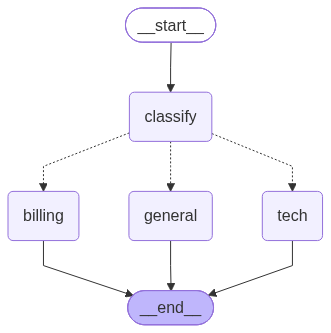

In [12]:
router_graph

Now invoke the same compiled graph on three different queries. We expect three different routes — and because the LLM call uses `with_structured_output` over a `Literal`, the router function can never receive an unknown value.

In [10]:
demo_queries = [
    'My last invoice shows the wrong amount, can you check?',
    'The dashboard returns a 500 error when I open the analytics tab.',
    'What are your office hours in Bangalore?',
]

for q in demo_queries:
    out = router_graph.invoke({'query': q, 'route': '', 'answer': ''})
    print(f"---- route: {out['route']} ----")
    print(f"  Q: {q}")
    print(f"  A: {out['answer'][:120]}...")

---- route: billing ----
  Q: My last invoice shows the wrong amount, can you check?
  A: [BILLING] We will look into the invoice for: My last invoice shows the wrong amount, can you check?...
---- route: tech ----
  Q: The dashboard returns a 500 error when I open the analytics tab.
  A: [TECH] Engineering will triage: The dashboard returns a 500 error when I open the analytics tab....
---- route: general ----
  Q: What are your office hours in Bangalore?
  A: [GENERAL] Routed to general support: What are your office hours in Bangalore?...


## Fan-out, fan-in: parallel branches in a DAG

Now let's exercise LangGraph's parallel scheduling. Three sibling research nodes do independent work after the same upstream node completes; LangGraph runs them concurrently and only fires the join node once all three have returned.

Now, we will
- declare a `ResearchState` whose `findings` field uses `Annotated[List[str], operator.add]` so parallel appends merge instead of clobber,
- write three `research_*_node` functions that each return a one-item list under `findings`,
- write a `synthesize_node` that runs only after all three complete,
- wire the **fan-out** (one source, three targets) and **fan-in** (three sources, one target) edges,
- invoke and print the merged findings to confirm parallel execution worked.

In [11]:
class ResearchState(TypedDict):
    topic:    str
    # Annotated reducer: parallel returns get appended together instead of overwriting.
    # operator.add concatenates lists; the same idea is what powers MessagesState under the hood.
    findings: Annotated[List[str], operator.add]
    summary:  str

Without that `Annotated[..., operator.add]` reducer, two parallel nodes returning `findings=[...]` would race and only the last writer would win. The reducer turns the field into an append-only log, which is exactly what fan-in needs.

In [12]:
def research_logs_node(state: ResearchState) -> dict:
    """Pretend to dig through application logs for the topic."""
    return {'findings': [f"[logs] error spike at 14:02 UTC for topic={state['topic']}"]}

def research_metrics_node(state: ResearchState) -> dict:
    """Pretend to query a metrics store."""
    return {'findings': [f"[metrics] p99 latency tripled for {state['topic']} between 14:00-14:10 UTC"]}

def research_past_incidents_node(state: ResearchState) -> dict:
    """Pretend to search a past-incidents knowledge base."""
    return {'findings': [f"[past-incidents] similar pattern in INC-742 for {state['topic']}, root cause was a hot shard"]}

Now the join node. It only sees state once **all three** parallel siblings have written; LangGraph blocks the synthesize step until every incoming edge has produced.

In [13]:
SYNTH_PROMPT = """Summarise the following findings into a single 2-sentence paragraph.

Findings:
{findings}
"""

def synthesize_node(state: ResearchState) -> dict:
    """Fan-in. Reads the merged `findings` list (built by the reducer from three parallel nodes)
    and produces one short summary."""
    bullet = '\n- '.join([''] + state['findings']).strip()
    resp = llm.invoke(SYNTH_PROMPT.format(findings=bullet)).content.strip()
    return {'summary': resp}

And the wiring. The fan-out is **three edges from one source**; the fan-in is **three edges into one target**. That topology — a directed acyclic graph with diamond shape — is the smallest non-trivial **DAG** and is what LangGraph schedules in parallel by construction.

In [14]:
fb = StateGraph(ResearchState)
fb.add_node('research_logs',           research_logs_node)
fb.add_node('research_metrics',        research_metrics_node)
fb.add_node('research_past_incidents', research_past_incidents_node)
fb.add_node('synthesize',              synthesize_node)

# Fan-out: START -> three sibling nodes
fb.add_edge(START, 'research_logs')
fb.add_edge(START, 'research_metrics')
fb.add_edge(START, 'research_past_incidents')

# Fan-in: three siblings -> synthesize
fb.add_edge('research_logs',           'synthesize')
fb.add_edge('research_metrics',        'synthesize')
fb.add_edge('research_past_incidents', 'synthesize')
fb.add_edge('synthesize', END)

fanout_graph = fb.compile()
print('Fan-out / fan-in graph compiled.')

Fan-out / fan-in graph compiled.


Now invoke it. We expect `findings` to contain **three** items (one from each parallel node) and `summary` to be a short LLM-written paragraph that references at least the log spike and the latency change.

In [15]:
fan_result = fanout_graph.invoke({'topic': 'checkout-service', 'findings': [], 'summary': ''})

print('---- fan-out / fan-in result ----')
print('Findings count:', len(fan_result['findings']))
for f in fan_result['findings']:
    print(' -', f)
print('Summary:')
print(' ', fan_result['summary'][:240] + '...' if len(fan_result['summary']) > 240 else fan_result['summary'])

---- fan-out / fan-in result ----
Findings count: 3
 - [logs] error spike at 14:02 UTC for topic=checkout-service
 - [metrics] p99 latency tripled for checkout-service between 14:00-14:10 UTC
 - [past-incidents] similar pattern in INC-742 for checkout-service, root cause was a hot shard
Summary:
  At 14:02 UTC, there was an error spike in the checkout-service, coinciding with a tripling of the p99 latency between 14:00-14:10 UTC. This pattern mirrors a previous incident (INC-742) where the root cause was identified as a hot shard.


## Incident report builder with verifier-driven retry

Finally, let's combine fan-out / fan-in with a conditional retry loop. After `synthesize_node` we add a `verify_node` that returns a Pydantic `Verdict`; if `not passed` and we are under the retry cap, the graph routes back to `synthesize_node`; otherwise it proceeds to `publish_node`.

Now, we will
- extend the state with `attempts`, `verdict_reasons`, `verdict_passed`, and `report`,
- define a Pydantic `Verdict(passed: bool, reasons: List[str])` schema,
- implement `verify_node` (LLM call with structured output) and `publish_node` (terminal),
- wire `add_conditional_edges` from `verify` back to `synthesize` (retry) or forward to `publish` (accept),
- compile the capstone DAG, render its mermaid diagram, and run it end-to-end with `InMemorySaver` and a `thread_id`.

In [16]:
class IncidentState(TypedDict):
    topic:           str
    findings:        Annotated[List[str], operator.add]
    summary:         str
    verdict_passed:  bool
    verdict_reasons: List[str]
    attempts:        int
    report:          str

MAX_RETRIES = 2  # synthesize is allowed at most this many extra attempts after the first

In [17]:
class Verdict(BaseModel):
    """Verifier output schema. `passed` is the boolean the conditional edge branches on;
    `reasons` is a short list of issues for the next synthesize attempt to address."""
    passed:  bool       = Field(description='True if the summary covers all three findings clearly')
    reasons: List[str]  = Field(default_factory=list,
                                description='Specific issues if passed=False; empty list otherwise')

Now the synthesize / verify / publish nodes. `synthesize_capstone_node` reads the `verdict_reasons` from the previous attempt (if any) and uses them to steer the next draft — that is what makes the retry loop actually improve things instead of repeating itself.

In [18]:
SYNTH_RETRY_PROMPT = """Write a 3-sentence incident summary for topic '{topic}'.

Findings:
{findings}

Previous reviewer issues (address all of these if present):
{reasons}
"""

def synthesize_capstone_node(state: IncidentState) -> dict:
    """Compose the incident summary, taking prior reviewer reasons into account.
    Increments `attempts` so the verify router can enforce MAX_RETRIES."""
    bullet  = '\n- '.join([''] + state['findings']).strip() or '(none)'
    reasons = '\n- '.join([''] + state.get('verdict_reasons', [])).strip() or '(none)'
    resp    = llm.invoke(SYNTH_RETRY_PROMPT.format(
        topic=state['topic'], findings=bullet, reasons=reasons)).content.strip()
    return {'summary': resp, 'attempts': state.get('attempts', 0) + 1}

In [19]:
VERIFY_PROMPT = """You are a strict reviewer. Decide if the SUMMARY below clearly references
every finding. If anything is missing or vague, set passed=False and list the specific issues.

Findings:
{findings}

Summary:
{summary}
"""

verify_llm = llm.with_structured_output(Verdict)

def verify_node(state: IncidentState) -> dict:
    """Score the current summary. Returns a Verdict whose `passed` field drives the conditional edge."""
    bullet = '\n- '.join([''] + state['findings']).strip() or '(none)'
    v: Verdict = verify_llm.invoke(VERIFY_PROMPT.format(
        findings=bullet, summary=state['summary']))
    return {'verdict_passed': v.passed, 'verdict_reasons': v.reasons}

def publish_node(state: IncidentState) -> dict:
    """Terminal node. Stamps the final report and is the only path to END."""
    body = (
        f"INCIDENT REPORT -- topic: {state['topic']}\n"
        f"attempts: {state['attempts']}\n\n"
        f"{state['summary']}\n"
    )
    return {'report': body}

And the conditional edge from `verify`. The router reads `verdict_passed` and `attempts` and chooses between `synthesize` (retry) and `publish` (accept). The `MAX_RETRIES` cap is what keeps this from becoming an unbounded loop when the verifier is hard to please.

In [20]:
def route_after_verify(state: IncidentState) -> str:
    """Retry until passed OR until MAX_RETRIES is exceeded; then publish whatever we have."""
    if state['verdict_passed']:
        return 'publish'
    if state['attempts'] > MAX_RETRIES:
        return 'publish'
    return 'synthesize'

cb = StateGraph(IncidentState)
cb.add_node('research_logs',           research_logs_node)
cb.add_node('research_metrics',        research_metrics_node)
cb.add_node('research_past_incidents', research_past_incidents_node)
cb.add_node('synthesize',              synthesize_capstone_node)
cb.add_node('verify',                  verify_node)
cb.add_node('publish',                 publish_node)

# Fan-out from START to three parallel research nodes
cb.add_edge(START, 'research_logs')
cb.add_edge(START, 'research_metrics')
cb.add_edge(START, 'research_past_incidents')

# Fan-in: all three -> synthesize
cb.add_edge('research_logs',           'synthesize')
cb.add_edge('research_metrics',        'synthesize')
cb.add_edge('research_past_incidents', 'synthesize')

# synthesize -> verify -> (retry to synthesize | accept to publish)
cb.add_edge('synthesize', 'verify')
cb.add_conditional_edges(
    'verify',
    route_after_verify,
    {'synthesize': 'synthesize', 'publish': 'publish'},
)
cb.add_edge('publish', END)

checkpointer = InMemorySaver()
app = cb.compile(checkpointer=checkpointer)
print('Capstone DAG compiled with checkpointer:', checkpointer.__class__.__name__)

Capstone DAG compiled with checkpointer: InMemorySaver


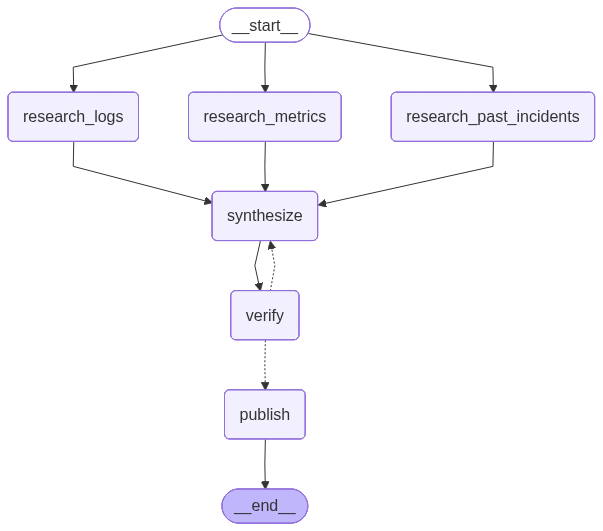

In [21]:
app

## Run with checkpointing

Now let's invoke the DAG with an explicit `thread_id`. The `InMemorySaver` snapshots state after every node, so a second `.invoke()` on the same `thread_id` resumes from the saved state instead of starting over.

Now, we will
- pick a `thread_id` and bind it through the `configurable` config dict,
- run the capstone end-to-end on a checkout-service incident,
- print the final report under a banner so the trace is readable,
- re-invoke with the same `thread_id` to confirm checkpointing surfaces the saved state.

In [22]:
thread_id = 'incident-demo-1'
config = {'configurable': {'thread_id': thread_id}}

initial: IncidentState = {
    'topic':           'checkout-service',
    'findings':        [],
    'summary':         '',
    'verdict_passed':  False,
    'verdict_reasons': [],
    'attempts':        0,
    'report':          '',
}

first_run = app.invoke(initial, config=config)

print('=== FIRST RUN ===')
print('attempts        :', first_run['attempts'])
print('verdict_passed  :', first_run['verdict_passed'])
print('verdict_reasons :', first_run['verdict_reasons'])
print('findings        :', len(first_run['findings']), 'items')
print('=== REPORT ===')
print(first_run['report'][:480] + ('...' if len(first_run['report']) > 480 else ''))

=== FIRST RUN ===
attempts        : 1
verdict_passed  : True
verdict_reasons : []
findings        : 3 items
=== REPORT ===
INCIDENT REPORT -- topic: checkout-service
attempts: 1

On [date], an incident was observed in the checkout-service, marked by an error spike at 14:02 UTC and a tripling of the p99 latency between 14:00 and 14:10 UTC. This pattern mirrors a previous incident (INC-742) where the root cause was identified as a hot shard. Further investigation is required to confirm if a similar issue is responsible for the current performance degradation.



Now re-invoke on the **same** `thread_id`. Because the checkpointer holds the saved state, `app.get_state(config)` returns the snapshot from the previous run — that is the basic resumability primitive that pairs with HITL pauses and crash recovery in production.

In [23]:
saved = app.get_state(config)

print('---- resume on same thread_id ----')
print('thread_id          :', thread_id)
print('saved next nodes   :', saved.next)
print('saved attempts     :', saved.values.get('attempts'))
print('saved verdict_pass :', saved.values.get('verdict_passed'))

---- resume on same thread_id ----
thread_id          : incident-demo-1
saved next nodes   : ()
saved attempts     : 1
saved verdict_pass : True


## Demo runs

Now let's exercise the DAG on three different incident topics, each on its own `thread_id`, so the per-thread checkpoint state stays isolated.

Now, we will
- pick three topics and three `thread_id` strings,
- invoke the capstone on each, with a fresh initial state,
- print each run under a `---- LABEL ----` banner including attempts, verdict, and a truncated report.

In [24]:
demo_topics = [
    ('checkout-flake',   'incident-demo-checkout'),
    ('search-latency',   'incident-demo-search'),
    ('payments-timeout', 'incident-demo-payments'),
]

for topic, tid in demo_topics:
    cfg = {'configurable': {'thread_id': tid}}
    init: IncidentState = {
        'topic':           topic,
        'findings':        [],
        'summary':         '',
        'verdict_passed':  False,
        'verdict_reasons': [],
        'attempts':        0,
        'report':          '',
    }
    out = app.invoke(init, config=cfg)
    print(f'---- {topic} (thread_id={tid}) ----')
    print(f"  attempts       : {out['attempts']}")
    print(f"  verdict_passed : {out['verdict_passed']}")
    print(f"  findings       : {len(out['findings'])} items")
    snippet = out['report'].replace('\n', ' ')[:120] + '...'
    print(f"  report snippet : {snippet}")

---- checkout-flake (thread_id=incident-demo-checkout) ----
  attempts       : 1
  verdict_passed : True
  findings       : 3 items
  report snippet : INCIDENT REPORT -- topic: checkout-flake attempts: 1  On [date], an incident was observed involving a significant error ...
---- search-latency (thread_id=incident-demo-search) ----
  attempts       : 1
  verdict_passed : True
  findings       : 3 items
  report snippet : INCIDENT REPORT -- topic: search-latency attempts: 1  On [date], an incident involving increased search latency was obse...
---- payments-timeout (thread_id=incident-demo-payments) ----
  attempts       : 1
  verdict_passed : True
  findings       : 3 items
  report snippet : INCIDENT REPORT -- topic: payments-timeout attempts: 1  On [date], an incident was observed involving a significant spik...


### Common pitfalls in controlled-workflow graphs
- Forgetting the reducer on parallel-write fields. Without `Annotated[List[str], operator.add]` two sibling nodes returning `findings=[...]` will race and only the last writer wins. <br>Mitigation: any field that is written by more than one upstream node MUST declare a reducer.
- Letting the verifier loop run unbounded. A strict reviewer will reject every draft; without a `MAX_RETRIES` cap and an attempts counter in state, the graph spins forever. <br>Mitigation: cap retries in the router function, not in the verifier prompt.
- Branching on free-text LLM output. If the router function string-matches on the model's prose, a temperature spike or a model swap silently sends traffic to the wrong node. <br>Mitigation: always use `with_structured_output` with a `Literal[...]` enum so the LLM CANNOT return an unknown route.